In [8]:
import numpy as np 
from pathlib import Path
import napari
import matplotlib.pyplot as plt
from fractal_generation.utils_fractals import (
    generate_random_gaussian_displacement,
)
import pyvista as pv

In [4]:
def get_visu_img(volume, name, cmap):
    nz, ny, nx = volume.shape

    iz, iy, ix = nz // 2, ny // 2, nx // 2

    fig = plt.figure(figsize=(10, 10), layout="none")

    gap = 0.005
    main = 0.72
    side = 0.24
    left = bottom = 0.02

    ax_xy = fig.add_axes([
        left, bottom + side + gap, main, main
    ])
    ax_yz = fig.add_axes([
        left + main + gap, bottom + side + gap, side, main
    ])
    ax_xz = fig.add_axes([
        left, bottom, main, side
    ])

    ax_xy.imshow(volume[iz, :, :], cmap=cmap, aspect="auto")
    ax_yz.imshow(volume[:, :, ix].T, cmap=cmap, aspect="auto")
    ax_xz.imshow(volume[:, iy, :], cmap=cmap, aspect="auto")

    for ax, label in [(ax_xy, "XY"), (ax_yz, "YZ"), (ax_xz, "XZ")]:
        ax.set_axis_off()
        ax.text(
            0.01, 0.99,
            label,
            transform=ax.transAxes,
            color="white",
            fontsize=25,
            fontweight="bold",
            ha="left",
            va="top",
        )


    output_path = Path(
        f"/Users/josephinelahmani/Desktop/nn_dis/results/plots/{name}_coupes.png"
    )

    fig.savefig(output_path, dpi=300, bbox_inches="tight", transparent=True, pad_inches=0)
    plt.show()

In [5]:
img_frac = np.load(Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_img.npy"))
img_cell = np.load(Path('/Users/josephinelahmani/Desktop/data/test_synth_3d/E_300.0_nu_0.45_nb_zones_im_00_seed_01_img.npy'))

# get_visu_img(img_cell[0], 'cell0', "gray")
# get_visu_img(img_cell[1], 'cell1', "gray")
# get_visu_img(img_frac[0], 'frac0', "gray")
# get_visu_img(img_frac[0], 'frac1', "gray")

In [6]:
ugt_frac = np.load(Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/fractal_74_13_funcs_ugt.npy"))
ugt_cell = np.load(Path('/Users/josephinelahmani/Desktop/data/test_synth_3d/E_300.0_nu_0.45_nb_zones_im_00_seed_01_ugt.npy'))

volume_ugt_cell_0 = ugt_cell[0, 0] * (img_cell[0] > 0.1)
volume_ugt_cell_1 = ugt_cell[1, 0] * (img_cell[0] > 0.1)
volume_ugt_cell_2 = ugt_cell[2, 0] * (img_cell[0] > 0.1)

volume_ugt_frac_0 = ugt_frac[0]# * (img_frac[0] > 0.1)
volume_ugt_frac_1 = ugt_frac[1]# * (img_frac[0] > 0.1)
volume_ugt_frac_2 = ugt_frac[2]# * (img_frac[0] > 0.1)

In [60]:
def show_flow(img, flow, name):
    mask = img[0] > 0.1

    u = flow * mask[None, ...]

    nz, ny, nx = img[0].shape

    spacing_xyz = np.array([2.0, 1.0, 1.0])

    grid = pv.ImageData(
        dimensions=(nx, ny, nz),
        spacing=tuple(spacing_xyz),
        origin=(0.0, 0.0, 0.0),
    )

    grid.point_data["intensity"] = img[0].ravel(order="C")

    grid.point_data["foreground"] = np.where(mask, img[0], 0).ravel(order="C")

    stride = 4

    ijk_zyx = np.argwhere(mask[::stride, ::stride, ::stride]) * stride

    z, y, x = ijk_zyx.T

    points_xyz = ijk_zyx[:, ::-1] * spacing_xyz

    vectors = u[:, z, y, x].T

    component_order = "zyx" 

    if component_order == "zyx":
        vectors_xyz = vectors[:, ::-1]
    elif component_order == "xyz":
        vectors_xyz = vectors
    else:
        raise ValueError("component_order must be 'zyx' or 'xyz'")

    vectors_xyz = vectors_xyz * spacing_xyz

    magnitude = np.linalg.norm(vectors_xyz, axis=1)

    nonzero = magnitude > 0
    cloud = pv.PolyData(points_xyz[nonzero])
    cloud["displacement"] = vectors_xyz[nonzero]
    cloud["magnitude"] = magnitude[nonzero]

    arrow_factor = 0.6

    arrow_geometry = pv.Arrow(
        shaft_radius=0.02,
        tip_radius=0.06,
        tip_length=0.20,
    )

    arrows = cloud.glyph(
        geom=arrow_geometry,
        orient="displacement",
        scale="magnitude",
        factor=arrow_factor,
    )

    plotter = pv.Plotter()
    plotter.set_background('black')

    plotter.add_volume(
        grid,
        scalars="foreground",
        cmap="gray",
        clim=(0, float(img[0].max())),
        shade=False,
        show_scalar_bar=False,
    )

    if cloud.n_points:
        plotter.add_mesh(
            arrows,
            scalars="magnitude",
            cmap="afmhot",
            show_scalar_bar=False,
        )

    plotter.view_xy()
    plotter.camera.zoom(1.2)
    output_path = Path(
            f"/Users/josephinelahmani/Desktop/nn_dis/results/plots/{name}_flow.png"
        )
    plotter.show(screenshot=str(output_path), auto_close=True)

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_35114/2090686036.py:88: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path), auto_close=True)


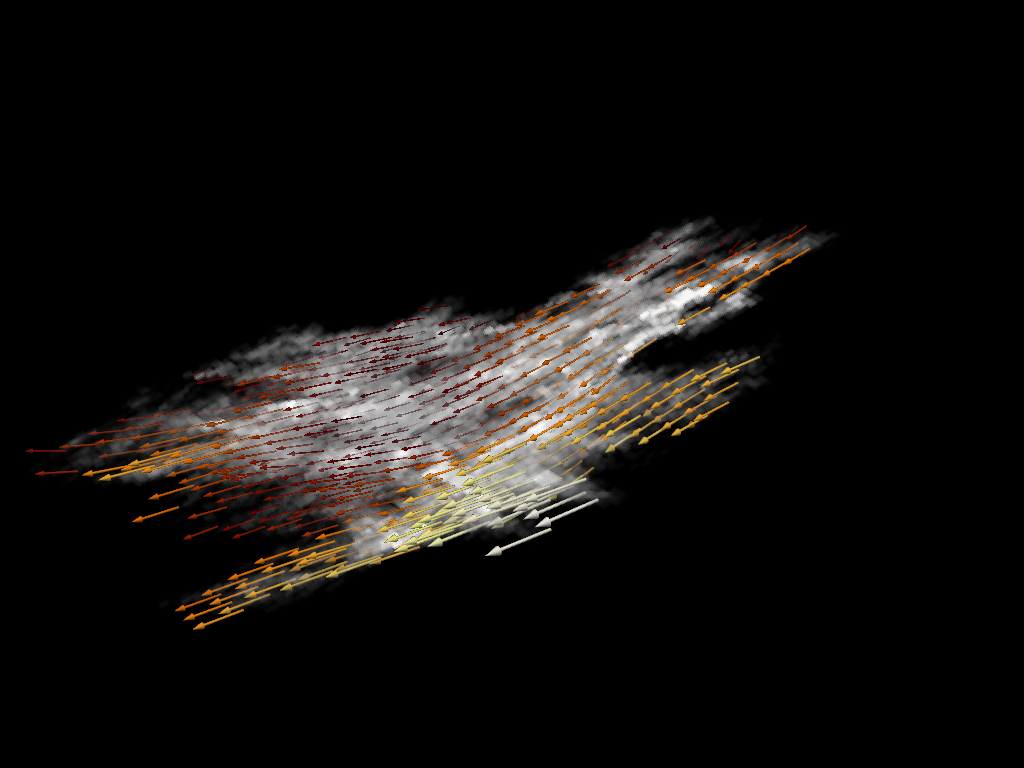

In [50]:
show_flow(img_frac, ugt_frac, 'frac')

In [64]:
print(ugt_cell.shape)

(3, 1, 22, 150, 155)


In [ ]:
viewer = napari.Viewer()
viewer.add_image(ugt_cell[0, 0])

<Image layer 'Image' at 0x166513ad0>

: 

/var/folders/q7/63xbgp7j3lx7627dsblbwqjw0000gn/T/ipykernel_35114/4201765085.py:88: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install trame-pyvista
  plotter.show(screenshot=str(output_path), auto_close=True)


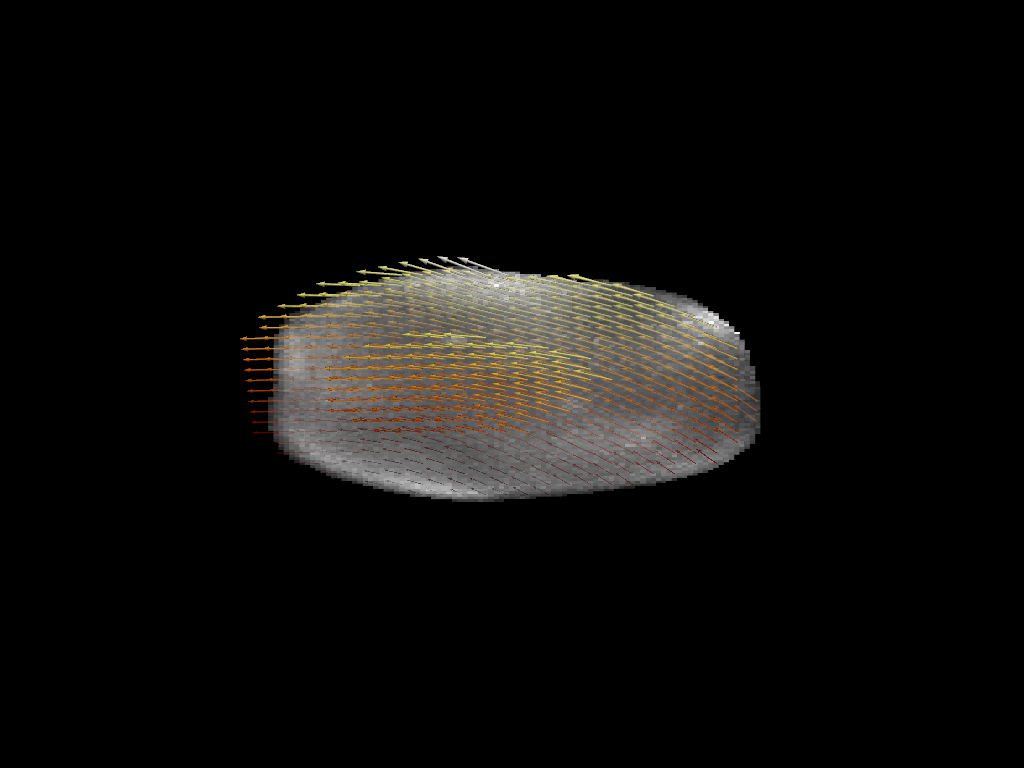

In [61]:
show_flow(img_cell, ugt_cell[:, 0], 'cell')

In [4]:
viewer_frac = napari.Viewer()
viewer_frac.add_image(img_frac, scale=(4.0, 1.0, 1.0), interpolation3d='nearest')
napari.run()

In [9]:
viewer_cell = napari.Viewer()
viewer_cell.add_image(img_cell, scale=(1.0, 0.13, 0.13), interpolation3d='nearest')
napari.run()

In [3]:
def plot_features_shape():
    features = [16, 32, 32, 64, 64, 64]

    multiplier_HW = [1, 1/2, 1/4, 1/8, 1/16, 1/16]
    multiplier_D = [1, 1, 1, 1/2, 1/4, 1/4]
    def mirror(values):
        return values + values[-2::-1]

    features = mirror(features)
    multiplier_HW = mirror(multiplier_HW)
    multiplier_D = mirror(multiplier_D)

    steps = np.arange(len(features))

    fig, ax_left = plt.subplots(figsize=(7, 3))
    ax_right = ax_left.twinx()

    fig.patch.set_alpha(0)
    ax_left.set_facecolor("none")
    ax_right.set_facecolor("none")

    line_features, = ax_left.plot(
        steps, features,
        color="green", linewidth=2,
        label="Features",
    )
    ax_left.set_ylabel("Features", color="green")
    ax_left.tick_params(axis="y", labelcolor="green")
    ax_left.set_yticks([16, 32, 48, 64])

    line_hw, = ax_right.plot(
        steps, multiplier_HW,
        color="red", linewidth=2,
        label="Height/Width multiplier",
    )
    line_d, = ax_right.plot(
        steps, multiplier_D,
        color="blue", linewidth=2,
        label="Depth multiplier",
    )

    ax_right.set_ylabel("Shape multiplier")
    ax_right.set_yticks([1/16, 1/8, 1/4, 1/2, 1])
    ax_right.set_yticklabels(["1/16", "1/8", "1/4", "1/2", "1"])

    ax_left.set_xticks(steps)
    ax_left.set_xticklabels([
        "Enc. 1", "Enc. 2", "Enc. 3", "Enc. 4",
        "", "Bottleneck", "",
        "Dec. 1", "Dec. 2", "Dec. 3", "Dec. 4",
    ])
    ax_left.set_xlabel("Network stage")

    ax_left.axvline(5, color="gray", linestyle=":", alpha=0.6)
    ax_left.grid(axis="y", linestyle="--", alpha=0.25)
    ax_left.set_axisbelow(True)

    lines = [line_features, line_hw, line_d]
    ax_left.legend(
        lines,
        [line.get_label() for line in lines],
        loc="upper center",
        bbox_to_anchor=(0.5, 1.18),
        ncol=3,
        frameon=False,
    )

    fig.tight_layout()

    output_path = Path(
        "/Users/josephinelahmani/Desktop/nn_dis/results/plots/features_and_shapes.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        transparent=True,
        bbox_inches="tight",
    )

    plt.show()

In [ ]:
rng = np.random.default_rng(seed=6)

u_grf = generate_random_gaussian_displacement(
    shape=[32, 128, 128],
    sigma_min=5,
    sigma_max=10,
    alpha_min=5,
    alpha_max=15,
    scale_z=1 / 0.13,
    rng=rng,
)


viewer = napari.Viewer()
img_grf = viewer.add_image(
    u_grf[2],
    name="Noise",
    interpolation3d="nearest",
    scale=(2.0, 1.0, 1.0),
    colormap="viridis",
)
img_grf.bounding_box.visible = True
img_grf.bounding_box.line_color = "white"
img_grf.bounding_box.point_color = "white"
img_grf.bounding_box.point_size = 1
img_grf.bounding_box.opacity = 0.8
img_grf.bounding_box.blending = "translucent"
img_grf.colorbar.visible = True

viewer.dims.ndisplay = 3
viewer.camera.angles = (-40, 0, 115)
viewer.camera.zoom = 6

output_dir = Path("/Users/josephinelahmani/Desktop/nn_dis/data/fractals/")
output_path = output_dir / "GRF.png"
viewer.screenshot(
    path=output_path,
    canvas_only=True,
    flash=False,
)
napari.run()